# Rekomendasi Lokasi Coffee Shop Kota Bandung (v2)
## KDE + KNN → integrasi fitur → K-Means vs HDBSCAN → peta rekomendasi web

**Alur pipeline**

| Tahap | Isi | Keluaran |
|---|---|---|
| 1. Input data geospasial | coffee shop (dataset v2), kampus, sekolah, perkantoran, pusat perbelanjaan, jalan, kepadatan penduduk | titik/garis/raster di UTM 48S |
| 2. Grid kandidat | sel heksagon H3 resolusi 9 (≈0,1 km²) di dalam Kota Bandung | ±1.600 sel |
| 3. KDE | kepadatan kompetitor & fasilitas pendukung (titik/km²) | `kde_*` |
| 4. KNN | jarak ke objek terdekat (cKDTree) | `d_*` |
| 5. Demografi & aksesibilitas | penduduk/km² (WorldPop 2025), jarak ke jalan utama, kerapatan jalan | `penduduk_km2`, `d_jalan_utama`, `kerapatan_jalan` |
| 6. Integrasi & normalisasi | log1p → z-score (StandardScaler), cek korelasi | matriks fitur |
| 7. Clustering | K-Means vs HDBSCAN (+ ablation set fitur) | label per sel |
| 8. Evaluasi | silhouette, DBI, CH, noise, koherensi spasial, stabilitas (ARI), hold-out & validasi temporal (AUC) | `tabel_evaluasi.csv` |
| 9. Interpretasi | kawasan **potensial / kompetitif / potensi rendah** | profil cluster |
| 10. Ekspor | GeoJSON + JSON untuk website React | `../web/public/data/` |

Data coffee shop berasal dari notebook `../notebook_extract_cafe/coffeshop_extract_v2.ipynb` (400 coffee shop final).

**Kebutuhan:** `pip install geopandas shapely pyproj h3 scikit-learn scipy rasterio requests matplotlib pandas numpy`

In [1]:
# Pasang paket ke Python yang sedang dipakai notebook ini (cukup sekali).
# Setelah selesai: Restart kernel, lalu Run All.
import sys
print("Python kernel:", sys.executable)
%pip install -q geopandas shapely pyproj pandas numpy matplotlib requests scikit-learn scipy h3 rasterio

Python kernel: /private/tmp/claude-501/-Users-teyok-Downloads-ExtractingDataSkripsi/0724e23e-948c-4914-b645-096e1971d3ec/scratchpad/venv/bin/python



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 0. Konfigurasi

In [2]:
import json, math, re, resource, sys, time, warnings
from contextlib import contextmanager
from datetime import datetime, timezone
from pathlib import Path

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd
import h3, requests, shapely
from shapely.geometry import Polygon, Point
from scipy.spatial import cKDTree
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, roc_auc_score)
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()                                     # folder notebook ini
EXTRACT = ROOT.parent / "notebook_extract_cafe" / "data"
RAW, INTERIM, OUTPUT = ROOT / "data/raw", ROOT / "data/interim", ROOT / "data/output"
WEB_DATA = ROOT.parent / "web" / "public" / "data"   # dibaca website React
for d in (RAW, INTERIM, OUTPUT, WEB_DATA):
    d.mkdir(parents=True, exist_ok=True)

# --- input dari pipeline ekstraksi v2
COFFEE_CSV     = EXTRACT / "final/coffeeshop_bandung.csv"
META_V2        = EXTRACT / "final/metadata.json"
BATAS_FILE     = EXTRACT / "raw/batas_kota_bandung.geojson"
KECAMATAN_FILE = EXTRACT / "raw/kecamatan_kota_bandung.geojson"
JALAN_FILE     = EXTRACT / "interim/jalan_osm.geojson"      # way highway+name (Overpass)

# --- input baru
POI_FILE = INTERIM / "osm_fasilitas.geojson"                # kampus, sekolah, kantor, belanja
OVERPASS_URL = "https://overpass-api.de/api/interpreter"
USER_AGENT = "skripsi-coffeeshop-bandung (rekomendasi lokasi)"
WORLDPOP_URL = ("https://data.worldpop.org/GIS/Population/Global_2015_2030/R2025A/2025/IDN/v1/"
                "100m/constrained/idn_pop_2025_CN_100m_R2025A_v1.tif")
WORLDPOP_FULL = RAW / "idn_pop_2025_CN_100m_R2025A_v1.tif"  # ±170 MB, diunduh sekali (di-.gitignore)
WORLDPOP_CLIP = RAW / "worldpop_bandung_2025.tif"           # potongan Bandung (kecil)

# --- parameter
CRS_METER    = 32748        # UTM 48S
H3_RES       = 9            # ±0,105 km² per sel
BUFFER_POI_M = 3000         # fasilitas di luar batas kota tetap dihitung (kurangi efek tepi)
BANDWIDTH_M  = 500          # bandwidth KDE (≈ 5–7 menit jalan kaki)
RADIUS_JALAN_M = 500        # radius kerapatan jalan
JALAN_UTAMA  = {"trunk", "trunk_link", "primary", "primary_link", "secondary", "secondary_link"}
PAKAI_MUNGKIN_TUTUP = True  # coffee shop berflag mungkin_tutup tetap dihitung kompetitor?
SEED = 42
rng = np.random.default_rng(SEED)

# --- pencatat waktu & memori (untuk analisis kebutuhan perangkat di laporan)
WAKTU = []
@contextmanager
def tahap(nama):
    t0 = time.perf_counter()
    yield
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    rss_mb = rss / 1e6 if sys.platform == "darwin" else rss / 1e3   # macOS: byte, Linux: KB
    WAKTU.append(dict(tahap=nama, detik=round(time.perf_counter() - t0, 2), puncak_memori_mb=round(rss_mb)))
    print(f"[{nama}] {WAKTU[-1]['detik']} s, puncak RAM proses {WAKTU[-1]['puncak_memori_mb']} MB")

## 1. Input data geospasial
### 1a. Batas wilayah & coffee shop (kompetitor)

In [3]:
with tahap("1a muat batas & coffee shop"):
    kota = gpd.read_file(BATAS_FILE).to_crs(CRS_METER)
    kecamatan = gpd.read_file(KECAMATAN_FILE).to_crs(CRS_METER)[["kecamatan", "geometry"]]
    AREA = kota.geometry.union_all()
    AREA_BUFFER = AREA.buffer(BUFFER_POI_M)

    cs = pd.read_csv(COFFEE_CSV)
    cs = cs[cs.masuk_final.astype(bool)]
    if not PAKAI_MUNGKIN_TUTUP:
        cs = cs[~cs.mungkin_tutup.astype(bool)]
    kopi = gpd.GeoDataFrame(cs, geometry=gpd.points_from_xy(cs.lon, cs.lat), crs=4326).to_crs(CRS_METER)
    kopi = kopi.reset_index(drop=True)
    meta_v2 = json.loads(META_V2.read_text(encoding="utf-8"))

print(f"Luas Kota Bandung {AREA.area/1e6:.1f} km², {len(kecamatan)} kecamatan")
print(f"Coffee shop (kompetitor): {len(kopi)}  | per sumber: {kopi.sumber.value_counts().to_dict()}")
print(f"Snapshot OSM coffee shop: {meta_v2['snapshot_osm']}")

[1a muat batas & coffee shop] 0.06 s, puncak RAM proses 279 MB
Luas Kota Bandung 167.6 km², 30 kecamatan
Coffee shop (kompetitor): 400  | per sumber: {'osm': 163, 'pemkot': 151, 'pemkot+osm': 86}
Snapshot OSM coffee shop: 2026-10-29 17:28:51+00:00


### 1b. Fasilitas pendukung dari OSM (Overpass)
| Kategori | Tag OSM |
|---|---|
| kampus | `amenity=university/college` |
| sekolah | `amenity=school` |
| kantor | `office=*`, `building=office`, `amenity=coworking_space` |
| belanja | `shop=mall/department_store`, `amenity=marketplace` |

Diunduh sekali lalu disimpan (`data/interim/osm_fasilitas.geojson`) supaya hasil bisa diulang dengan snapshot yang sama.
Objek area (kampus, mall) diwakili titik tengahnya. Objek dengan kategori & nama sama dalam radius 100 m dianggap duplikat (mis. node + gedung).

In [4]:
def kategori_fasilitas(t):
    a, s = t.get("amenity"), t.get("shop")
    if a in ("university", "college"):
        return "kampus"
    if a == "school":
        return "sekolah"
    if s in ("mall", "department_store") or a == "marketplace":
        return "belanja"
    if "office" in t or t.get("building") == "office" or a == "coworking_space":
        return "kantor"
    return None

def unduh_fasilitas():
    minx, miny, maxx, maxy = gpd.GeoSeries([AREA_BUFFER], crs=CRS_METER).to_crs(4326).total_bounds
    bb = f"{miny},{minx},{maxy},{maxx}"
    q = f"""[out:json][timeout:300];
    ( nwr["amenity"~"^(university|college|school|coworking_space|marketplace)$"]({bb});
      nwr["office"]({bb}); nwr["building"="office"]({bb});
      nwr["shop"~"^(mall|department_store)$"]({bb}); );
    out center tags;"""
    r = requests.post(OVERPASS_URL, data={"data": q}, headers={"User-Agent": USER_AGENT}, timeout=600)
    r.raise_for_status()
    js = r.json()
    rows = []
    for e in js["elements"]:
        t = e.get("tags", {})
        k = kategori_fasilitas(t)
        lat = e.get("lat", e.get("center", {}).get("lat"))
        lon = e.get("lon", e.get("center", {}).get("lon"))
        if k and lat is not None:
            rows.append(dict(osm_key=f"{e['type']}/{e['id']}", kategori=k, nama=t.get("name", ""),
                             tag=";".join(f"{a}={t[a]}" for a in ("amenity", "office", "shop", "building") if a in t),
                             lat=lat, lon=lon))
    g = gpd.GeoDataFrame(rows, geometry=gpd.points_from_xy([r["lon"] for r in rows], [r["lat"] for r in rows]), crs=4326)
    g["snapshot_osm"] = js["osm3s"]["timestamp_osm_base"] + " "      # spasi: cegah dibaca sebagai datetime
    g.to_file(POI_FILE, driver="GeoJSON")
    return g

with tahap("1b fasilitas OSM"):
    fas = gpd.read_file(POI_FILE) if POI_FILE.exists() else unduh_fasilitas()
    SNAPSHOT_FASILITAS = str(fas.snapshot_osm.iat[0]).strip()
    fas = fas.to_crs(CRS_METER)
    fas = fas[fas.within(AREA_BUFFER)].reset_index(drop=True)
    # deduplikasi: kategori + nama sama dalam 100 m
    nama = fas.nama.fillna("").str.upper().str.replace(r"[^A-Z0-9]", "", regex=True).values
    xy = np.c_[fas.geometry.x, fas.geometry.y]
    dup = {max(i, j) for i, j in cKDTree(xy).query_pairs(100)
           if nama[i] and nama[i] == nama[j] and fas.kategori.iat[i] == fas.kategori.iat[j]}
    fas = fas.drop(index=list(dup)).reset_index(drop=True)
    fas["di_kota"] = fas.within(AREA)

print(f"Snapshot OSM fasilitas: {SNAPSHOT_FASILITAS} | duplikat dibuang: {len(dup)}")
fas.groupby("kategori").agg(total_dalam_buffer=("di_kota", "size"), di_dalam_kota=("di_kota", "sum"))

[1b fasilitas OSM] 0.02 s, puncak RAM proses 282 MB
Snapshot OSM fasilitas: 2026-11-07 12:37:17+00:00 | duplikat dibuang: 96


,total_dalam_buffer,di_dalam_kota
kategori,,
belanja,102,91
kampus,122,106
kantor,784,710
sekolah,659,539


### 1c. Jaringan jalan
Dipakai ulang dari pipeline ekstraksi (`jalan_osm.geojson`, semua way `highway` yang bernama). Jalan utama = trunk, primary, secondary (+ link). Tol (`motorway`) tidak dihitung karena tidak bisa diakses langsung dari kawasan.

In [5]:
with tahap("1c jalan"):
    jalan = gpd.read_file(JALAN_FILE).to_crs(CRS_METER)
    SNAPSHOT_JALAN = str(jalan.snapshot_osm.iat[0]).strip()
    jalan = jalan[~jalan.highway.isin(["motorway", "motorway_link", "construction", "proposed"])].reset_index(drop=True)
    jalan_utama = jalan[jalan.highway.isin(JALAN_UTAMA)]
print(f"Ruas jalan bernama: {len(jalan):,} (utama: {len(jalan_utama):,}) | panjang total {jalan.length.sum()/1000:,.0f} km")

[1c jalan] 0.11 s, puncak RAM proses 307 MB
Ruas jalan bernama: 20,023 (utama: 2,990) | panjang total 2,592 km


### 1d. Kepadatan penduduk (WorldPop 2025, 100 m, *constrained*)
Raster WorldPop memperkirakan jumlah penduduk per piksel 100 m × 100 m (hanya di piksel yang ada bangunannya). File Indonesia diunduh sekali, dipotong ke Kota Bandung + buffer, lalu file besarnya boleh dihapus.

Sumber: WorldPop (2025), *Global2 R2025A*, CC BY 4.0, doi:10.5258/SOTON/WP00845.

In [6]:
import rasterio
from rasterio.mask import mask as rio_mask

def siapkan_worldpop():
    if WORLDPOP_CLIP.exists():
        return
    if not WORLDPOP_FULL.exists():
        print("Mengunduh WorldPop Indonesia (±170 MB) ...")
        with requests.get(WORLDPOP_URL, stream=True, timeout=600) as r:
            r.raise_for_status()
            with open(WORLDPOP_FULL, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
    with rasterio.open(WORLDPOP_FULL) as src:
        geom = gpd.GeoSeries([AREA_BUFFER], crs=CRS_METER).to_crs(src.crs)
        arr, tr = rio_mask(src, list(geom), crop=True)
        prof = src.profile | dict(height=arr.shape[1], width=arr.shape[2], transform=tr, compress="deflate")
    with rasterio.open(WORLDPOP_CLIP, "w", **prof) as dst:
        dst.write(arr)

with tahap("1d worldpop"):
    siapkan_worldpop()
    with rasterio.open(WORLDPOP_CLIP) as src:
        pop = src.read(1).astype("float64")
        pop[(pop == src.nodata) | ~np.isfinite(pop) | (pop < 0)] = 0
        rr, cc = np.nonzero(pop)
        xs, ys = rasterio.transform.xy(src.transform, rr, cc)
        pix = pd.DataFrame(dict(lon=np.asarray(xs), lat=np.asarray(ys), jiwa=pop[rr, cc]))
pix_kota = gpd.GeoDataFrame(pix, geometry=gpd.points_from_xy(pix.lon, pix.lat), crs=4326).to_crs(CRS_METER)
print(f"Piksel berpenduduk: {len(pix):,} | estimasi penduduk Kota Bandung (WorldPop): "
      f"{pix_kota[pix_kota.within(AREA)].jiwa.sum():,.0f} jiwa")

[1d worldpop] 0.04 s, puncak RAM proses 331 MB


Piksel berpenduduk: 42,379 | estimasi penduduk Kota Bandung (WorldPop): 2,575,163 jiwa


## 2. Grid kandidat lokasi (H3 resolusi 9)
Setiap heksagon adalah satu "kandidat lokasi". Sel diambil kalau titik tengahnya di dalam Kota Bandung.

In [7]:
with tahap("2 grid H3"):
    kota_wgs = kota.to_crs(4326).geometry.union_all()
    cells = sorted(h3.geo_to_cells(kota_wgs.__geo_interface__, res=H3_RES))
    grid = gpd.GeoDataFrame({"h3": cells},
                            geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in cells],
                            crs=4326).to_crs(CRS_METER)
    cen = grid.geometry.centroid
    grid["x"], grid["y"] = cen.x.values, cen.y.values
    grid["lat"] = [h3.cell_to_latlng(c)[0] for c in grid.h3]
    grid["lon"] = [h3.cell_to_latlng(c)[1] for c in grid.h3]
    titik = gpd.GeoDataFrame(geometry=cen, crs=CRS_METER)
    grid["kecamatan"] = gpd.sjoin_nearest(titik, kecamatan, how="left").groupby(level=0).kecamatan.first().values
    grid = grid.reset_index(drop=True)
    G = np.c_[grid.x, grid.y]
    LUAS_SEL_KM2 = grid.area.mean() / 1e6
print(f"Jumlah sel: {len(grid):,} | luas rata-rata sel {LUAS_SEL_KM2:.3f} km² | total {grid.area.sum()/1e6:.1f} km²")

[2 grid H3] 0.07 s, puncak RAM proses 349 MB
Jumlah sel: 1,599 | luas rata-rata sel 0.104 km² | total 167.0 km²


## 3. KDE — kepadatan kompetitor & fasilitas pendukung
Kernel Gaussian dengan bandwidth tetap `BANDWIDTH_M`. Hasil dikonversi menjadi **intensitas (titik per km²)**:

$$\hat\lambda(x) = n \cdot \frac{1}{n}\sum_{i=1}^{n}\frac{1}{2\pi h^2}\exp\left(-\frac{\lVert x-x_i\rVert^2}{2h^2}\right)\times 10^6$$

Sebagai pembanding, bandwidth dari aturan Scott dan cross-validation (log-likelihood) dihitung untuk coffee shop; 500 m tetap dipakai karena alasan substantif (jangkauan jalan kaki).

In [8]:
KAT_FASILITAS = ["kampus", "sekolah", "kantor", "belanja"]
def xy(g):
    return np.c_[g.geometry.x, g.geometry.y]
KOPI_XY = xy(kopi)
FAS_XY = {k: xy(fas[fas.kategori == k]) for k in KAT_FASILITAS}

def kde(src, target=None, h=BANDWIDTH_M):
    target = G if target is None else target
    kd = KernelDensity(bandwidth=h, kernel="gaussian").fit(src)
    return len(src) * np.exp(kd.score_samples(target)) * 1e6

with tahap("3 KDE"):
    scott = float(np.mean(KOPI_XY.std(axis=0)) * len(KOPI_XY) ** (-1 / 6))
    cv = GridSearchCV(KernelDensity(kernel="gaussian"),
                      {"bandwidth": [150, 250, 350, 500, 750, 1000, 1500]}, cv=5).fit(KOPI_XY)
    grid["kde_kopi"] = kde(KOPI_XY)
    for k in KAT_FASILITAS:
        grid[f"kde_{k}"] = kde(FAS_XY[k])
BW_INFO = dict(scott_m=round(scott), cv_m=int(cv.best_params_["bandwidth"]), dipakai_m=BANDWIDTH_M)
print(f"Bandwidth coffee shop | Scott: {scott:.0f} m | CV: {BW_INFO['cv_m']} m | dipakai: {BANDWIDTH_M} m")
grid.filter(like="kde_").describe().round(1)

[3 KDE] 0.09 s, puncak RAM proses 349 MB
Bandwidth coffee shop | Scott: 1022 m | CV: 500 m | dipakai: 500 m


,kde_kopi,kde_kampus,kde_sekolah,kde_kantor,kde_belanja
count,1599.0,1599.0,1599.0,1599.0,1599.0
mean,2.4,0.6,3.2,4.2,0.5
std,3.8,1.0,2.8,5.0,0.7
min,0.0,0.0,0.0,0.0,0.0
25%,0.2,0.0,1.0,1.1,0.0
50%,0.8,0.2,2.3,2.6,0.2
75%,2.6,0.9,4.4,4.7,0.7
max,25.2,5.2,13.8,29.1,4.3


## 4. KNN — jarak ke objek terdekat
`cKDTree` (jarak Euclidean di UTM, meter). Untuk kompetitor dipakai jarak ke tetangga ke-1 (`d_kopi_1`) dan rata-rata 3 tetangga terdekat (`d_kopi_3`).

In [9]:
def jarak_knn(src, k=1, target=None):
    target = G if target is None else target
    d, _ = cKDTree(src).query(target, k=k)
    return d if k == 1 else d.mean(axis=1)

with tahap("4 KNN"):
    grid["d_kopi_1"] = jarak_knn(KOPI_XY, 1)
    grid["d_kopi_3"] = jarak_knn(KOPI_XY, 3)
    for k in KAT_FASILITAS:
        grid[f"d_{k}"] = jarak_knn(FAS_XY[k])
grid.filter(like="d_").describe().round(0)

[4 KNN] 0.0 s, puncak RAM proses 349 MB


,d_kopi_1,d_kopi_3,d_kampus,d_sekolah,d_kantor,d_belanja
count,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0
mean,723.0,922.0,1212.0,423.0,471.0,1053.0
std,589.0,610.0,893.0,301.0,385.0,749.0
min,8.0,39.0,13.0,4.0,13.0,5.0
25%,288.0,452.0,511.0,206.0,204.0,485.0
50%,554.0,796.0,947.0,352.0,365.0,859.0
75%,998.0,1257.0,1727.0,562.0,608.0,1429.0
max,3532.0,3852.0,4167.0,1807.0,2601.0,4038.0


## 5. Demografi & aksesibilitas
- `penduduk_km2` = jumlah penduduk WorldPop di dalam sel ÷ luas sel.
- `d_jalan_utama` = jarak titik tengah sel ke jalan utama terdekat (m).
- `kerapatan_jalan` = panjang jalan bernama dalam radius 500 m ÷ luas lingkaran (km/km²).

In [10]:
with tahap("5 demografi & aksesibilitas"):
    pix["h3"] = [h3.latlng_to_cell(la, lo, H3_RES) for la, lo in zip(pix.lat, pix.lon)]
    jiwa_sel = pix.groupby("h3").jiwa.sum()
    grid["penduduk"] = grid.h3.map(jiwa_sel).fillna(0)
    grid["penduduk_km2"] = grid.penduduk / (grid.area / 1e6)

    titik = gpd.GeoDataFrame(geometry=gpd.points_from_xy(grid.x, grid.y), crs=CRS_METER)
    grid["d_jalan_utama"] = (gpd.sjoin_nearest(titik, jalan_utama[["geometry"]], distance_col="d")
                             .groupby(level=0).d.min().values)
    lingkaran = titik.buffer(RADIUS_JALAN_M)
    garis = jalan.geometry.values
    idx_l, idx_j = jalan.sindex.query(lingkaran, predicate="intersects")
    pjg = shapely.length(shapely.intersection(garis[idx_j], lingkaran.values[idx_l]))
    grid["kerapatan_jalan"] = (pd.Series(pjg).groupby(idx_l).sum().reindex(range(len(grid)), fill_value=0).values
                               / 1000) / (math.pi * (RADIUS_JALAN_M / 1000) ** 2)
grid[["penduduk_km2", "d_jalan_utama", "kerapatan_jalan"]].describe().round(1)

[5 demografi & aksesibilitas] 0.65 s, puncak RAM proses 396 MB


,penduduk_km2,d_jalan_utama,kerapatan_jalan
count,1599.0,1599.0,1599.0
mean,15375.2,386.9,10.6
std,6367.9,489.1,5.1
min,0.0,0.0,0.0
25%,11265.2,94.8,6.6
50%,16757.0,241.1,10.5
75%,20271.0,479.9,14.0
max,27493.6,3733.7,26.8


## 6. Integrasi fitur & normalisasi
Fitur dikelompokkan menjadi empat blok. Semua fitur sangat menceng (banyak nilai kecil, sedikit nilai besar), jadi diberi `log1p` lalu distandarkan menjadi z-score (`StandardScaler`, rata-rata 0, simpangan baku 1) supaya satuan meter, titik/km², dan jiwa/km² setara.

Empat set fitur untuk **ablation study** (apakah penambahan blok fitur memperbaiki hasil):

| Set | Isi |
|---|---|
| `KNN` | 6 fitur jarak |
| `KDE` | 5 fitur kepadatan |
| `KNN+KDE` | 11 fitur |
| `LENGKAP` | KNN + KDE + demografi + aksesibilitas (14 fitur) — **set utama** |

[6 normalisasi] 0.0 s, puncak RAM proses 396 MB


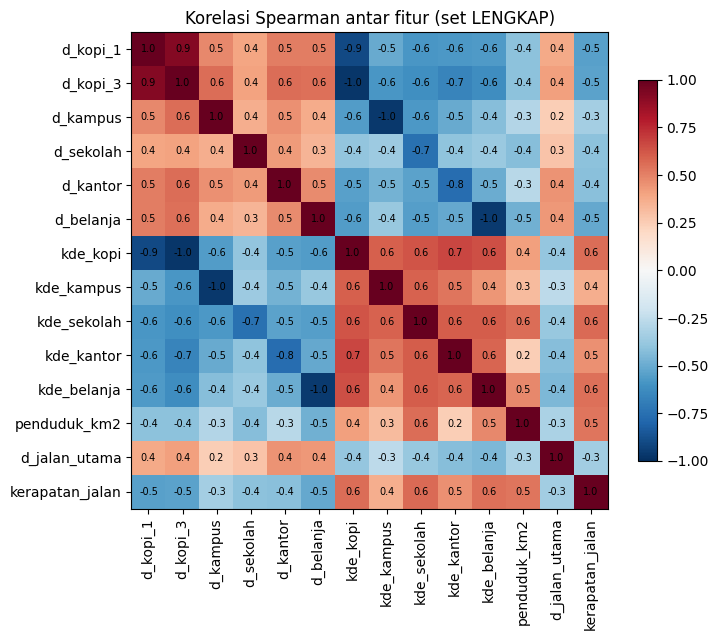

Pasangan |r| > 0,8 (redundan):
  d_kopi_1         ~ d_kopi_3         r = +0.92
  d_kopi_1         ~ kde_kopi         r = -0.90
  d_kopi_3         ~ kde_kopi         r = -0.97
  d_kampus         ~ kde_kampus       r = -0.97
  d_belanja        ~ kde_belanja      r = -0.96


In [11]:
F_KNN = ["d_kopi_1", "d_kopi_3", "d_kampus", "d_sekolah", "d_kantor", "d_belanja"]
F_KDE = ["kde_kopi", "kde_kampus", "kde_sekolah", "kde_kantor", "kde_belanja"]
F_DEMOGRAFI = ["penduduk_km2"]
F_AKSES = ["d_jalan_utama", "kerapatan_jalan"]
SETS = {"KNN": F_KNN, "KDE": F_KDE, "KNN+KDE": F_KNN + F_KDE,
        "LENGKAP": F_KNN + F_KDE + F_DEMOGRAFI + F_AKSES}
UTAMA = "LENGKAP"

def matriks(cols, df=None):
    df = grid if df is None else df
    return StandardScaler().fit_transform(np.log1p(df[cols].values))

with tahap("6 normalisasi"):
    X = {nama: matriks(cols) for nama, cols in SETS.items()}

corr = np.log1p(grid[SETS[UTAMA]]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.3))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, shrink=.8); ax.set_title("Korelasi Spearman antar fitur (set LENGKAP)")
plt.tight_layout(); plt.savefig(OUTPUT / "korelasi_fitur.png", dpi=140); plt.show()
TINGGI = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr) for b in corr.columns[i + 1:]
          if abs(corr.loc[a, b]) > .8]
print("Pasangan |r| > 0,8 (redundan):")
for a, b, r in TINGGI:
    print(f"  {a:16s} ~ {b:16s} r = {r:+.2f}")

## 7. Clustering
### 7a. Fungsi evaluasi
- **Silhouette** (↑, −1..1), **Davies-Bouldin** (↓), **Calinski-Harabasz** (↑). Untuk HDBSCAN dihitung hanya pada sel non-noise, dan **% noise** dilaporkan terpisah.
- **Koherensi spasial**: proporsi pasangan sel bertetangga yang berlabel sama vs label diacak (z-score). Makin besar = cluster membentuk kawasan yang menyatu di peta.

In [12]:
IDX = {c: i for i, c in enumerate(grid.h3)}
TETANGGA = np.array([(i, IDX[n]) for i, c in enumerate(grid.h3) for n in h3.grid_ring(c, 1)
                     if n in IDX and IDX[n] > i])

def koherensi_spasial(labels, n_perm=199):
    m = (labels[TETANGGA[:, 0]] != -1) & (labels[TETANGGA[:, 1]] != -1)
    P = TETANGGA[m]
    obs = np.mean(labels[P[:, 0]] == labels[P[:, 1]])
    lab, valid, sims = labels.copy(), np.where(labels != -1)[0], []
    for _ in range(n_perm):
        lab[valid] = rng.permutation(labels[valid])
        sims.append(np.mean(lab[P[:, 0]] == lab[P[:, 1]]))
    return obs, (obs - np.mean(sims)) / np.std(sims)

def evaluasi(Xs, labels):
    m = labels != -1
    k = len(set(labels[m]))
    hasil = dict(n_cluster=k, noise_pct=100 * (1 - m.mean()))
    if k >= 2:
        hasil.update(silhouette=silhouette_score(Xs[m], labels[m]),
                     davies_bouldin=davies_bouldin_score(Xs[m], labels[m]),
                     calinski_harabasz=calinski_harabasz_score(Xs[m], labels[m]))
        hasil["tetangga_sama_label"], hasil["z_spasial"] = koherensi_spasial(labels)
    return hasil

### 7b. K-Means — memilih k
k = 2..10 diuji dengan elbow (inertia), silhouette, dan Davies-Bouldin. Aturan: **k dengan silhouette tertinggi pada rentang 3–8** (k = 2 hanya memisahkan pusat vs pinggiran, terlalu kasar untuk tiga jenis kawasan).

[7b K-Means pilih k] 0.46 s, puncak RAM proses 441 MB


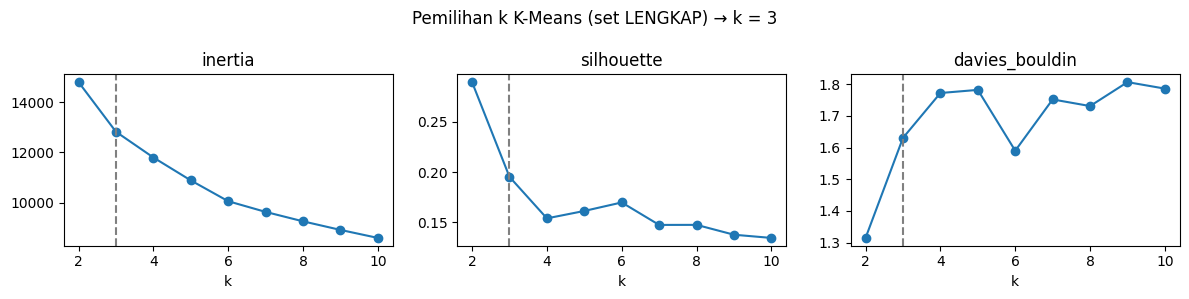

,k,inertia,silhouette,davies_bouldin
0,2,14799.526,0.290,1.315
1,3,12820.902,0.195,1.631
2,4,11796.198,0.154,1.772
3,5,10883.455,0.161,1.782
4,6,10054.215,0.170,1.590
5,7,9628.227,0.147,1.752
6,8,9252.727,0.147,1.731
7,9,8910.812,0.137,1.807
8,10,8591.825,0.134,1.786


In [13]:
def pilih_kmeans(Xs, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(k, n_init=10, random_state=SEED).fit(Xs)
        rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Xs, km.labels_),
                         davies_bouldin=davies_bouldin_score(Xs, km.labels_)))
    tab = pd.DataFrame(rows)
    return int(tab[tab.k.between(3, 8)].sort_values("silhouette", ascending=False).k.iloc[0]), tab

with tahap("7b K-Means pilih k"):
    k_utama, tab_k = pilih_kmeans(X[UTAMA])
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, col in zip(ax, ["inertia", "silhouette", "davies_bouldin"]):
    a.plot(tab_k.k, tab_k[col], "o-"); a.axvline(k_utama, ls="--", c="gray"); a.set_title(col); a.set_xlabel("k")
plt.suptitle(f"Pemilihan k K-Means (set {UTAMA}) → k = {k_utama}"); plt.tight_layout()
plt.savefig(OUTPUT / "pemilihan_k.png", dpi=140); plt.show()
tab_k.round(3)

### 7c. HDBSCAN — grid search parameter
Parameter: `min_cluster_size`, `min_samples`, `cluster_selection_method` (eom/leaf). Aturan pemilihan bertingkat (tingkat pertama yang punya kandidat dipakai, lalu silhouette non-noise tertinggi):
1. noise ≤ 30% dan ≥ 3 cluster; 2. noise ≤ 30% dan ≥ 2 cluster; 3. noise ≤ 50% dan ≥ 2 cluster; 4. noise terkecil dengan ≥ 2 cluster.

Tingkat yang terpakai ikut dilaporkan: kalau HDBSCAN hanya lolos di tingkat 3–4, data tidak punya struktur kepadatan yang jelas.

In [14]:
def pilih_hdbscan(Xs, mcs_list=(10, 15, 25, 40, 60), ms_list=(1, 3, 5, 10, 20), metode=("eom", "leaf")):
    rows = []
    for meth in metode:
        for mcs in mcs_list:
            for ms in ms_list:
                lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=meth,
                              copy=True).fit_predict(Xs)
                m = lab != -1; k = len(set(lab[m]))
                rows.append(dict(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=meth,
                                 n_cluster=k, noise_pct=100 * (1 - m.mean()),
                                 silhouette=silhouette_score(Xs[m], lab[m]) if k >= 2 else np.nan))
    tab = pd.DataFrame(rows)
    for t, (nmax, kmin) in enumerate([(30, 3), (30, 2), (50, 2)], 1):
        ok = tab[(tab.noise_pct <= nmax) & (tab.n_cluster >= kmin)].dropna()
        if len(ok):
            b = ok.sort_values("silhouette", ascending=False).iloc[0]
            break
    else:
        t, b = 4, tab[tab.n_cluster >= 2].sort_values("noise_pct").iloc[0]
    par = dict(min_cluster_size=int(b.min_cluster_size), min_samples=int(b.min_samples),
               cluster_selection_method=b.cluster_selection_method)
    return par, tab, t

with tahap("7c HDBSCAN grid search"):
    par_hdb, tab_hdb, tingkat_hdb = pilih_hdbscan(X[UTAMA])
print(f"Parameter terpilih: {par_hdb} (aturan tingkat {tingkat_hdb})")
print("Konfigurasi dengan >= 3 cluster dan noise <= 30%:",
      len(tab_hdb[(tab_hdb.n_cluster >= 3) & (tab_hdb.noise_pct <= 30)]), "dari", len(tab_hdb))
tab_hdb.sort_values("silhouette", ascending=False).head(10).round(3)

[7c HDBSCAN grid search] 0.8 s, puncak RAM proses 445 MB
Parameter terpilih: {'min_cluster_size': 10, 'min_samples': 1, 'cluster_selection_method': 'eom'} (aturan tingkat 2)
Konfigurasi dengan >= 3 cluster dan noise <= 30%: 0 dari 50


,min_cluster_size,min_samples,cluster_selection_method,n_cluster,noise_pct,silhouette
7,15,5,eom,2,94.684,0.363
32,15,5,leaf,2,94.684,0.363
36,25,3,leaf,2,93.621,0.294
11,25,3,eom,2,93.621,0.294
27,10,5,leaf,4,93.183,0.270
3,10,10,eom,2,64.540,0.256
28,10,10,leaf,2,64.540,0.256
6,15,3,eom,2,65.791,0.247
1,10,3,eom,2,65.791,0.247
5,15,1,eom,2,60.788,0.230


## 8. Evaluasi & perbandingan
### 8a. Metrik internal + koherensi spasial untuk semua set fitur (ablation)
Untuk setiap set fitur parameter dipilih ulang dengan aturan yang sama (adil untuk kedua algoritma).

In [15]:
LABEL, PARAM, baris = {}, {}, []
with tahap("8a clustering semua set"):
    for nama, Xs in X.items():
        k_best, _ = pilih_kmeans(Xs)
        p_hdb, _, tingkat = (par_hdb, None, tingkat_hdb) if nama == UTAMA else pilih_hdbscan(Xs)
        PARAM[(nama, "K-Means")], PARAM[(nama, "HDBSCAN")] = dict(n_clusters=k_best), p_hdb
        LABEL[(nama, "K-Means")] = KMeans(k_best, n_init=10, random_state=SEED).fit_predict(Xs)
        LABEL[(nama, "HDBSCAN")] = HDBSCAN(**p_hdb, copy=True).fit_predict(Xs)
        for alg in ("K-Means", "HDBSCAN"):
            baris.append(dict(set_fitur=nama, algoritma=alg, parameter=str(PARAM[(nama, alg)]),
                              tingkat_aturan=(tingkat if alg == "HDBSCAN" else np.nan),
                              **evaluasi(Xs, LABEL[(nama, alg)])))
hasil = pd.DataFrame(baris)
hasil.round(3)

[8a clustering semua set] 3.65 s, puncak RAM proses 495 MB


,set_fitur,algoritma,parameter,tingkat_aturan,n_cluster,noise_pct,silhouette,davies_bouldin,calinski_harabasz,tetangga_sama_label,z_spasial
0,KNN,K-Means,{'n_clusters': 3},NaN,3,0.000,0.218,1.491,708.443,0.772,66.626
1,KNN,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 1, 'cl...",2.0,2,16.385,0.234,0.900,28.178,0.991,6.436
2,KDE,K-Means,{'n_clusters': 4},NaN,4,0.000,0.330,1.274,940.109,0.866,84.460
3,KDE,HDBSCAN,"{'min_cluster_size': 60, 'min_samples': 1, 'cl...",1.0,3,28.393,0.450,0.724,792.445,0.993,49.127
4,KNN+KDE,K-Means,{'n_clusters': 3},NaN,3,0.000,0.235,1.476,782.805,0.836,71.297
5,KNN+KDE,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 1, 'cl...",2.0,2,10.569,0.438,0.582,79.560,0.997,13.643
6,LENGKAP,K-Means,{'n_clusters': 3},NaN,3,0.000,0.195,1.631,595.352,0.822,63.002
7,LENGKAP,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 1, 'cl...",2.0,2,22.577,0.125,1.208,14.119,0.994,7.051


### 8b. Stabilitas (bootstrap 80%, 20 ulangan, Adjusted Rand Index)

In [16]:
def cluster_ulang(Xs, alg, par, seed=SEED):
    if alg == "K-Means":
        return KMeans(par["n_clusters"], n_init=10, random_state=seed).fit_predict(Xs)
    return HDBSCAN(**par, copy=True).fit_predict(Xs)

def stabilitas(Xs, alg, par, labels_full, n_iter=20, frac=.8):
    ari = []
    for _ in range(n_iter):
        idx = rng.choice(len(Xs), int(frac * len(Xs)), replace=False)
        ari.append(adjusted_rand_score(labels_full[idx], cluster_ulang(Xs[idx], alg, par, int(rng.integers(1e6)))))
    return np.mean(ari), np.std(ari)

with tahap("8b stabilitas"):
    stab = [dict(set_fitur=n, algoritma=a, **dict(zip(["ARI_mean", "ARI_std"],
                 stabilitas(X[n], a, PARAM[(n, a)], LABEL[(n, a)]))))
            for n in X for a in ("K-Means", "HDBSCAN")]
hasil = hasil.merge(pd.DataFrame(stab), on=["set_fitur", "algoritma"], how="left")
hasil[["set_fitur", "algoritma", "n_cluster", "noise_pct", "silhouette", "davies_bouldin",
       "calinski_harabasz", "z_spasial", "ARI_mean", "ARI_std"]].round(3)

[8b stabilitas] 1.79 s, puncak RAM proses 495 MB


,set_fitur,algoritma,n_cluster,noise_pct,silhouette,davies_bouldin,calinski_harabasz,z_spasial,ARI_mean,ARI_std
0,KNN,K-Means,3,0.000,0.218,1.491,708.443,66.626,0.889,0.068
1,KNN,HDBSCAN,2,16.385,0.234,0.900,28.178,6.436,0.607,0.234
2,KDE,K-Means,4,0.000,0.330,1.274,940.109,84.460,0.924,0.114
3,KDE,HDBSCAN,3,28.393,0.450,0.724,792.445,49.127,0.481,0.291
4,KNN+KDE,K-Means,3,0.000,0.235,1.476,782.805,71.297,0.957,0.021
5,KNN+KDE,HDBSCAN,2,10.569,0.438,0.582,79.560,13.643,0.633,0.182
6,LENGKAP,K-Means,3,0.000,0.195,1.631,595.352,63.002,0.886,0.122
7,LENGKAP,HDBSCAN,2,22.577,0.125,1.208,14.119,7.051,0.531,0.320


## 9. Interpretasi: kawasan potensial, kompetitif, potensi rendah
Dua indeks per sel (rata-rata z-score fitur setelah log1p):
- **Indeks pendukung** `z_pendukung` = rata-rata z dari `kde_kampus`, `kde_sekolah`, `kde_kantor`, `kde_belanja`, `penduduk_km2`, `kerapatan_jalan` (permintaan + akses).
- **Indeks kompetisi** `z_kompetisi` = z dari `kde_kopi`.
- **Skor peluang** = `z_pendukung − z_kompetisi`.

Aturan pelabelan **per cluster** (memakai rata-rata cluster):
| Kelas | Syarat |
|---|---|
| **Potensi rendah** | `z_pendukung` cluster < 0 (di bawah rata-rata kota) |
| **Potensial** | `z_pendukung` ≥ 0 dan skor peluang ≥ 0 (pendukung lebih kuat daripada kompetisi) |
| **Kompetitif** | `z_pendukung` ≥ 0 dan skor peluang < 0 (kompetitor sudah padat) |

Noise HDBSCAN diberi kelas *tidak terklasifikasi*. Tidak ada pemaksaan: kalau sebuah algoritma tidak menghasilkan cluster yang lolos syarat **potensial**, memang tidak ada kawasan potensial menurut algoritma itu (dan itu dilaporkan sebagai hasil).

In [17]:
F_PENDUKUNG = ["kde_kampus", "kde_sekolah", "kde_kantor", "kde_belanja", "penduduk_km2", "kerapatan_jalan"]
Zf = pd.DataFrame(StandardScaler().fit_transform(np.log1p(grid[F_PENDUKUNG + ["kde_kopi"]])),
                  columns=F_PENDUKUNG + ["kde_kopi"])
grid["z_pendukung"] = Zf[F_PENDUKUNG].mean(axis=1).values
grid["z_kompetisi"] = Zf["kde_kopi"].values
grid["skor_peluang"] = grid.z_pendukung - grid.z_kompetisi
SEL_KOPI = set(h3.latlng_to_cell(p.y, p.x, H3_RES) for p in kopi.to_crs(4326).geometry)
grid["ada_coffee_shop"] = grid.h3.isin(SEL_KOPI)
grid["n_coffee_shop"] = grid.h3.map(pd.Series([h3.latlng_to_cell(p.y, p.x, H3_RES)
                                               for p in kopi.to_crs(4326).geometry]).value_counts()).fillna(0).astype(int)
NAMA_KELAS = {"potensial": "Kawasan potensial", "kompetitif": "Kawasan kompetitif",
              "rendah": "Kawasan potensi rendah", "noise": "Tidak terklasifikasi (noise)"}

def kelas_cluster(prof):
    """prof: DataFrame per cluster dengan z_pendukung, skor_peluang -> Series kelas."""
    kel = pd.Series("rendah", index=prof.index)
    ok = prof.z_pendukung >= 0
    kel[ok & (prof.skor_peluang >= 0)] = "potensial"
    kel[ok & (prof.skor_peluang < 0)] = "kompetitif"
    kel[kel.index == -1] = "noise"
    return kel

def profil(labels):
    g = grid.assign(cluster=labels)
    p = g.groupby("cluster").agg(
        n_sel=("h3", "size"), luas_km2=("geometry", lambda s: s.area.sum() / 1e6),
        n_coffee_shop=("n_coffee_shop", "sum"),
        pct_sel_ada_coffee_shop=("ada_coffee_shop", lambda s: 100 * s.mean()),
        d_kopi_1_median_m=("d_kopi_1", "median"), kde_kopi_median=("kde_kopi", "median"),
        d_kampus_median_m=("d_kampus", "median"), d_kantor_median_m=("d_kantor", "median"),
        d_belanja_median_m=("d_belanja", "median"), penduduk_km2_median=("penduduk_km2", "median"),
        kerapatan_jalan_median=("kerapatan_jalan", "median"), d_jalan_utama_median_m=("d_jalan_utama", "median"),
        z_pendukung=("z_pendukung", "mean"), z_kompetisi=("z_kompetisi", "mean"),
        skor_peluang=("skor_peluang", "mean"))
    p["kelas"] = kelas_cluster(p)
    p["nama_kelas"] = p.kelas.map(NAMA_KELAS)
    p["kecamatan_utama"] = [", ".join(g[g.cluster == c].kecamatan.value_counts().head(3).index) for c in p.index]
    return p

PROFIL = {}
for alg in ("K-Means", "HDBSCAN"):
    PROFIL[alg] = profil(LABEL[(UTAMA, alg)])
    print(f"\n=== {alg} (set {UTAMA}) | kelas: {PROFIL[alg].kelas.value_counts().to_dict()}")
    display(PROFIL[alg].round(2))

for alg, col in (("K-Means", "km"), ("HDBSCAN", "hdb")):
    grid[f"cluster_{col}"] = LABEL[(UTAMA, alg)]
    grid[f"kelas_{col}"] = grid[f"cluster_{col}"].map(PROFIL[alg].kelas)


=== K-Means (set LENGKAP) | kelas: {'rendah': 1, 'kompetitif': 1, 'potensial': 1}


,n_sel,luas_km2,n_coffee_shop,pct_sel_ada_coffee_shop,d_kopi_1_median_m,kde_kopi_median,d_kampus_median_m,d_kantor_median_m,d_belanja_median_m,penduduk_km2_median,kerapatan_jalan_median,d_jalan_utama_median_m,z_pendukung,z_kompetisi,skor_peluang,kelas,nama_kelas,kecamatan_utama
cluster,,,,,,,,,,,,,,,,,,
0,598,62.45,4,0.67,1104.72,0.10,1808.32,673.32,1423.83,12669.81,6.39,443.80,-0.68,-0.79,0.11,rendah,Kawasan potensi rendah,"Bandung Kulon, Arcamanik, Rancasari"
1,336,35.11,338,48.51,181.90,6.43,446.63,162.84,379.60,20237.61,14.20,90.84,0.92,1.47,-0.55,kompetitif,Kawasan kompetitif,"Coblong, Lengkong, Bandung Wetan"
2,665,69.46,57,7.67,471.60,1.11,731.51,315.77,763.88,17857.71,11.37,234.69,0.15,-0.03,0.18,potensial,Kawasan potensial,"Buahbatu, Sukasari, Kiaracondong"



=== HDBSCAN (set LENGKAP) | kelas: {'noise': 1, 'rendah': 1, 'kompetitif': 1}


,n_sel,luas_km2,n_coffee_shop,pct_sel_ada_coffee_shop,d_kopi_1_median_m,kde_kopi_median,d_kampus_median_m,d_kantor_median_m,d_belanja_median_m,penduduk_km2_median,kerapatan_jalan_median,d_jalan_utama_median_m,z_pendukung,z_kompetisi,skor_peluang,kelas,nama_kelas,kecamatan_utama
cluster,,,,,,,,,,,,,,,,,,
-1,361,37.71,276,35.46,268.05,2.73,504.32,195.41,580.65,17481.06,12.48,84.68,0.43,0.70,-0.27,noise,Tidak terklasifikasi (noise),"Coblong, Gedebage, Cicendo"
0,1228,128.27,118,6.92,657.17,0.56,1109.27,436.37,964.40,16543.36,9.66,286.97,-0.13,-0.22,0.08,rendah,Kawasan potensi rendah,"Cidadap, Arcamanik, Buahbatu"
1,10,1.04,5,50.00,162.92,4.86,359.64,288.45,1165.27,19413.18,19.19,257.50,0.63,1.15,-0.53,kompetitif,Kawasan kompetitif,"Lengkong, Sukasari"


### 9b. Validasi eksternal
Dua uji "apakah peta ini sesuai dengan lokasi coffee shop sebenarnya":
1. **Hold-out spasial (5-fold)**: 20% coffee shop disembunyikan, fitur kompetitor (`d_kopi_1`, `d_kopi_3`, `kde_kopi`) dihitung ulang dari 80% sisanya, cluster ulang, lalu skor sel = proporsi sel di cluster-nya yang berisi coffee shop latih. **AUC**: seberapa baik skor membedakan sel berisi coffee shop tersembunyi dari sel lain (0,5 = acak).
2. **Validasi temporal**: coffee shop yang **pertama kali tercatat di Pemkot tahun 2023–2024** disembunyikan; model dibangun dari coffee shop lama saja. Diukur: (a) AUC yang sama, (b) persentase coffee shop baru yang jatuh di kawasan *potensial* + *kompetitif* dibanding persentase luas kawasan itu (kalau model berguna, persentase coffee shop baru > persentase luas).

Keduanya mengukur kecocokan lokasi (di mana coffee shop cenderung berdiri), bukan profitabilitas.

In [18]:
def sel_dari(g):
    return np.array([h3.latlng_to_cell(p.y, p.x, H3_RES) for p in g.to_crs(4326).geometry])

def bangun_ulang(latih):
    g = grid.copy()
    K = xy(latih)
    g["d_kopi_1"], g["d_kopi_3"], g["kde_kopi"] = jarak_knn(K, 1), jarak_knn(K, 3), kde(K)
    return g

def skor_auc(lab, latih, uji):
    ada_latih = grid.h3.isin(sel_dari(latih)).values
    skor = pd.Series(lab).map(pd.Series(ada_latih).groupby(lab).mean()).values
    y = grid.h3.isin(sel_dari(uji)).values & ~ada_latih
    return roc_auc_score(y, skor), y.sum()

def holdout_auc(alg, par, n_fold=5):
    out = []
    for tr, te in KFold(n_fold, shuffle=True, random_state=SEED).split(kopi):
        g = bangun_ulang(kopi.iloc[tr])
        lab = cluster_ulang(matriks(SETS[UTAMA], g), alg, par)
        out.append(skor_auc(lab, kopi.iloc[tr], kopi.iloc[te])[0])
    return np.mean(out), np.std(out)

baru = kopi.tahun_pertama.fillna(0) >= 2023
def validasi_temporal(alg, par):
    g = bangun_ulang(kopi[~baru])
    Xs = matriks(SETS[UTAMA], g)
    lab = cluster_ulang(Xs, alg, par)
    auc, n_sel = skor_auc(lab, kopi[~baru], kopi[baru])
    # kelas kawasan dari model lama
    g2 = grid.assign(cluster=lab)
    Zg = StandardScaler().fit_transform(np.log1p(g[["kde_kopi"]]))[:, 0]
    pr = g2.assign(z_kompetisi=Zg, skor_peluang=g2.z_pendukung - Zg).groupby("cluster")[["z_pendukung", "skor_peluang"]].mean()
    kel = pd.Series(lab).map(kelas_cluster(pr)).values
    sel_baru = pd.Series(sel_dari(kopi[baru])).map(IDX)
    kel_baru = pd.Series(kel[sel_baru.dropna().astype(int)])
    aktif = np.isin(kel, ["potensial", "kompetitif"])
    return dict(AUC_temporal=auc, n_baru=int(baru.sum()),
                pct_baru_di_potensial_kompetitif=100 * kel_baru.isin(["potensial", "kompetitif"]).mean(),
                pct_luas_potensial_kompetitif=100 * aktif.mean(),
                pct_baru_di_potensial=100 * (kel_baru == "potensial").mean(),
                pct_luas_potensial=100 * (kel == "potensial").mean())

with tahap("9b validasi eksternal"):
    val = []
    for alg in ("K-Means", "HDBSCAN"):
        mu, sd = holdout_auc(alg, PARAM[(UTAMA, alg)])
        val.append(dict(set_fitur=UTAMA, algoritma=alg, AUC_holdout=mu, AUC_holdout_std=sd,
                        **validasi_temporal(alg, PARAM[(UTAMA, alg)])))
val = pd.DataFrame(val)
print(f"Coffee shop baru (pertama tercatat 2023–2024): {int(baru.sum())}")
val.round(3)

[9b validasi eksternal] 0.35 s, puncak RAM proses 495 MB
Coffee shop baru (pertama tercatat 2023–2024): 63


,set_fitur,algoritma,AUC_holdout,AUC_holdout_std,AUC_temporal,n_baru,pct_baru_di_potensial_kompetitif,pct_luas_potensial_kompetitif,pct_baru_di_potensial,pct_luas_potensial
0,LENGKAP,K-Means,0.713,0.038,0.760,63,98.387,66.417,11.29,41.901
1,LENGKAP,HDBSCAN,0.576,0.036,0.651,63,3.226,6.629,0.00,3.377


### 9c. Ringkasan perbandingan K-Means vs HDBSCAN (set utama)

In [19]:
ringkasan = hasil[hasil.set_fitur == UTAMA].merge(val, on=["set_fitur", "algoritma"], how="left")
KOLOM = ["algoritma", "parameter", "n_cluster", "noise_pct", "silhouette", "davies_bouldin", "calinski_harabasz",
         "z_spasial", "ARI_mean", "AUC_holdout", "AUC_temporal", "pct_baru_di_potensial_kompetitif",
         "pct_luas_potensial_kompetitif"]
display(ringkasan[KOLOM].round(3))
setuju = pd.crosstab(grid.kelas_km.rename("K-Means"), grid.kelas_hdb.rename("HDBSCAN"))
print("Kesepakatan kelas kawasan (jumlah sel):"); display(setuju)

,algoritma,parameter,n_cluster,noise_pct,silhouette,davies_bouldin,calinski_harabasz,z_spasial,ARI_mean,AUC_holdout,AUC_temporal,pct_baru_di_potensial_kompetitif,pct_luas_potensial_kompetitif
0,K-Means,{'n_clusters': 3},3,0.000,0.195,1.631,595.352,63.002,0.886,0.713,0.760,98.387,66.417
1,HDBSCAN,"{'min_cluster_size': 10, 'min_samples': 1, 'cl...",2,22.577,0.125,1.208,14.119,7.051,0.531,0.576,0.651,3.226,6.629


Kesepakatan kelas kawasan (jumlah sel):


HDBSCAN,kompetitif,noise,rendah
K-Means,,,
kompetitif,4,198,134
potensial,6,119,540
rendah,0,44,554


## 10. Peta hasil

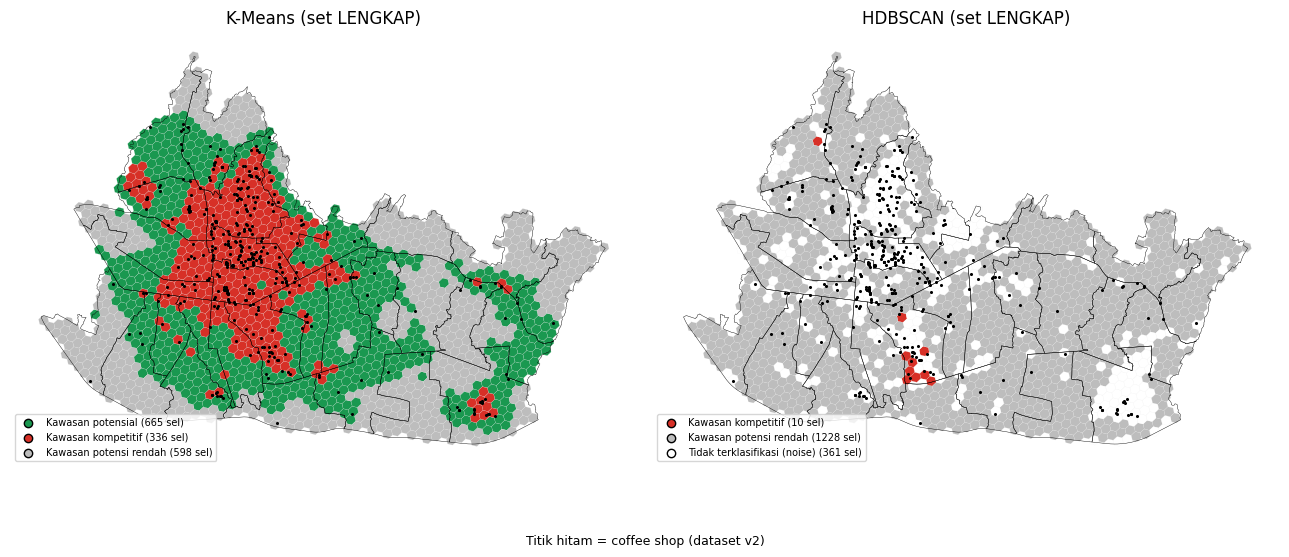

In [20]:
WARNA_KELAS = {"potensial": "#1a9850", "kompetitif": "#d73027", "rendah": "#bdbdbd", "noise": "#ffffff"}
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
for a, (alg, col) in zip(ax, (("K-Means", "km"), ("HDBSCAN", "hdb"))):
    grid.plot(color=grid[f"kelas_{col}"].map(WARNA_KELAS), ax=a, linewidth=.1, edgecolor="#eeeeee")
    kecamatan.boundary.plot(ax=a, color="k", lw=.3)
    kopi.plot(ax=a, color="k", markersize=1.5)
    for k, w in WARNA_KELAS.items():
        if (grid[f"kelas_{col}"] == k).any():
            a.scatter([], [], color=w, edgecolors="k", label=f"{NAMA_KELAS[k]} ({(grid[f'kelas_{col}'] == k).sum()} sel)")
    a.legend(loc="lower left", fontsize=7); a.set_title(f"{alg} (set {UTAMA})"); a.set_axis_off()
fig.suptitle("Titik hitam = coffee shop (dataset v2)", y=.04, fontsize=9)
plt.tight_layout(); plt.savefig(OUTPUT / "peta_kmeans_vs_hdbscan.png", dpi=160); plt.show()

## 10b. Ringkasan per kecamatan (untuk laporan & sistem rekomendasi)
Website memeringkat kecamatan sesuai preferensi pengguna (target pasar, toleransi kompetisi). Untuk itu setiap kecamatan diringkas:
- rata-rata z-score fitur pendukung & kompetisi (log1p → z, sama seperti bagian 9),
- persentase luas tiap jenis kawasan (K-Means & HDBSCAN),
- sel kawasan potensial terbaik (skor peluang tertinggi),
- kisaran harga coffee shop dari GoFood (kalau `scrape_harga_gofood.ipynb` sudah dijalankan).

In [21]:
GOFOOD_FILE = INTERIM / "gofood_outlet.csv"
ZK = pd.DataFrame(StandardScaler().fit_transform(np.log1p(grid[F_PENDUKUNG + ["kde_kopi"]])),
                  columns=[f"z_{c}" for c in F_PENDUKUNG + ["kde_kopi"]])
gk = pd.concat([grid.drop(columns="geometry").reset_index(drop=True), ZK], axis=1)
gk["luas_km2"] = grid.area.values / 1e6

gofood = pd.read_csv(GOFOOD_FILE) if GOFOOD_FILE.exists() else None
if gofood is not None:
    gofood = gofood[gofood.kopi & (gofood.price_level > 0)]
    print(f"GoFood: {len(gofood)} outlet kopi bertingkat harga")
else:
    print("GoFood belum diambil: jalankan scrape_harga_gofood.ipynb dulu (kisaran harga dilewati)")

def stat_harga(df):
    if df is None or not len(df):
        return dict(n=0)
    vc = df.price_level.value_counts()
    return dict(n=int(len(df)), median_level=float(df.price_level.median()), mean_level=round(float(df.price_level.mean()), 2),
                distribusi={int(k): int(v) for k, v in vc.items()})

KEC = []
for nama, d in gk.groupby("kecamatan"):
    r = dict(kecamatan=nama, n_sel=len(d), luas_km2=round(d.luas_km2.sum(), 2),
             penduduk=round(float(d.penduduk.sum())), n_coffee_shop=int(d.n_coffee_shop.sum()),
             kopi_per_km2=round(d.n_coffee_shop.sum() / d.luas_km2.sum(), 2),
             d_kopi_1_median_m=round(float(d.d_kopi_1.median())),
             skor_peluang_mean=round(float(d.skor_peluang.mean()), 3),
             z=dict({c: round(float(d[f"z_{c}"].mean()), 3) for c in F_PENDUKUNG + ["kde_kopi"]},
                    pendukung=round(float(d.z_pendukung.mean()), 3), kompetisi=round(float(d.z_kompetisi.mean()), 3)))
    for col in ("km", "hdb"):
        r[f"pct_{col}"] = {k: round(100 * v, 1) for k, v in d[f"kelas_{col}"].value_counts(normalize=True).items()}
        top = d[d[f"kelas_{col}"] == "potensial"].nlargest(3, "skor_peluang")
        r[f"sel_terbaik_{col}"] = [dict(h3=t.h3, lat=round(t.lat, 6), lon=round(t.lon, 6), skor_peluang=round(t.skor_peluang, 3),
                                         d_kopi_1=round(t.d_kopi_1), penduduk_km2=round(t.penduduk_km2)) for t in top.itertuples()]
    r["harga_gofood"] = stat_harga(gofood[gofood.kecamatan == nama] if gofood is not None else None)
    KEC.append(r)
HARGA_KOTA = stat_harga(gofood)
pd.DataFrame([dict(kecamatan=k["kecamatan"], potensial_km=k["pct_km"].get("potensial", 0),
                   kompetitif_km=k["pct_km"].get("kompetitif", 0), coffee_shop=k["n_coffee_shop"],
                   z_pendukung=k["z"]["pendukung"], z_kompetisi=k["z"]["kompetisi"],
                   harga_n=k["harga_gofood"]["n"], harga_median=k["harga_gofood"].get("median_level")) for k in KEC]
             ).sort_values("potensial_km", ascending=False)

GoFood: 246 outlet kopi bertingkat harga


,kecamatan,potensial_km,kompetitif_km,coffee_shop,z_pendukung,z_kompetisi,harga_n,harga_median
9,Bojongloa Kaler,83.3,16.7,2,0.560,-0.245,6,2.0
20,Kiaracondong,79.6,13.0,5,0.189,-0.303,13,2.0
1,Antapani,74.4,2.3,6,0.004,-0.073,2,3.0
27,Sukasari,70.5,11.5,11,0.035,-0.119,11,3.0
13,Cibeunying Kidul,69.2,17.9,7,0.477,0.070,13,2.0
23,Panyileukan,67.3,0.0,1,-0.172,-0.491,0,NaN
11,Buahbatu,63.9,2.8,5,-0.046,-0.520,8,2.0
8,Batununggal,63.8,36.2,12,0.488,0.528,9,2.0
10,Bojongloa Kidul,63.8,6.4,8,0.068,-0.333,8,2.0
3,Astanaanyar,60.0,40.0,3,0.700,0.209,4,2.0


## 11. Simpan hasil & ekspor data website

In [22]:
with tahap("11 simpan & ekspor"):
    # --- keluaran analisis
    grid.drop(columns=["x", "y"]).to_crs(4326).to_file(OUTPUT / "grid_fitur_cluster.geojson", driver="GeoJSON")
    tabel_eval = hasil.merge(val, on=["set_fitur", "algoritma"], how="left")
    tabel_eval.to_csv(OUTPUT / "tabel_evaluasi.csv", index=False)
    for alg in PROFIL:
        PROFIL[alg].to_csv(OUTPUT / f"profil_cluster_{alg.lower().replace('-', '')}.csv")
    tab_k.to_csv(OUTPUT / "pemilihan_k_kmeans.csv", index=False)
    tab_hdb.to_csv(OUTPUT / "gridsearch_hdbscan.csv", index=False)

    # --- data website (WGS84, angka dibulatkan supaya file kecil)
    FITUR_WEB = F_KNN + F_KDE + F_DEMOGRAFI + F_AKSES
    gw = grid.to_crs(4326)
    gw["geometry"] = shapely.set_precision(gw.geometry.values, 1e-6)
    kol = (["h3", "kecamatan", "lat", "lon", "n_coffee_shop", "cluster_km", "kelas_km", "cluster_hdb", "kelas_hdb",
            "z_pendukung", "z_kompetisi", "skor_peluang"] + FITUR_WEB + ["geometry"])
    gw = gw[kol].copy()
    for c in FITUR_WEB + ["z_pendukung", "z_kompetisi", "skor_peluang"]:
        gw[c] = gw[c].round(3 if c.startswith("z_") or c == "skor_peluang" else 1)
    gw["lat"], gw["lon"] = gw.lat.round(6), gw.lon.round(6)
    (WEB_DATA / "grid.geojson").write_text(gw.to_json(drop_id=True), encoding="utf-8")

    kw = kopi.to_crs(4326)
    kw = kw.assign(lat=kw.geometry.y.round(6), lon=kw.geometry.x.round(6))[
        ["nama", "alamat", "kategori", "sumber", "geo_presisi", "sumber_koordinat", "ketidakpastian_m",
         "tahun_pertama", "terakhir_tercatat", "mungkin_tutup", "lat", "lon"]]
    kw = kw.astype(object).where(kw.notna(), None)
    (WEB_DATA / "coffee_shop.json").write_text(json.dumps(kw.to_dict("records"), ensure_ascii=False), encoding="utf-8")

    fw = fas[fas.di_kota].to_crs(4326)
    fw = pd.DataFrame(dict(kategori=fw.kategori, nama=fw.nama.fillna(""),
                           lat=fw.geometry.y.round(6), lon=fw.geometry.x.round(6)))
    (WEB_DATA / "fasilitas.json").write_text(json.dumps(fw.to_dict("records"), ensure_ascii=False), encoding="utf-8")

    kc = kecamatan.to_crs(4326).copy()
    kc["geometry"] = kc.geometry.simplify(0.00005)
    (WEB_DATA / "kecamatan.geojson").write_text(kc.to_json(drop_id=True), encoding="utf-8")
    (WEB_DATA / "kecamatan_stat.json").write_text(json.dumps(dict(
        kecamatan=KEC, harga_kota=HARGA_KOTA,
        sumber_harga=("GoFood (halaman daftar publik), tingkat harga 1: <Rp16rb, 2: Rp16–40rb, 3: Rp40–100rb, 4: >Rp100rb"
                      if gofood is not None else None),
        diambil_harga=(str(pd.read_csv(GOFOOD_FILE).diambil.max()) if gofood is not None else None)),
        ensure_ascii=False), encoding="utf-8")

    def rec(df):
        df = df.reset_index()
        return json.loads(df.to_json(orient="records", double_precision=4))

    meta = dict(
        dibuat=datetime.now(timezone.utc).isoformat(timespec="seconds"),
        sumber=dict(coffee_shop=f"Dataset v2 ({len(kopi)} coffee shop; Disbudpar Kota Bandung + OSM, snapshot {meta_v2['snapshot_osm']})",
                    fasilitas=f"OpenStreetMap via Overpass, snapshot {SNAPSHOT_FASILITAS}",
                    jalan=f"OpenStreetMap via Overpass, snapshot {SNAPSHOT_JALAN}",
                    penduduk="WorldPop Global2 R2025A, 2025, 100 m constrained (CC BY 4.0)"),
        parameter=dict(h3_res=H3_RES, luas_sel_km2=round(LUAS_SEL_KM2, 4), bandwidth=BW_INFO,
                       radius_kerapatan_jalan_m=RADIUS_JALAN_M, set_utama=UTAMA, fitur=SETS,
                       f_pendukung=F_PENDUKUNG, kmeans=PARAM[(UTAMA, "K-Means")], hdbscan=PARAM[(UTAMA, "HDBSCAN")],
                       hdbscan_tingkat_aturan=tingkat_hdb, pakai_mungkin_tutup=PAKAI_MUNGKIN_TUTUP),
        jumlah=dict(sel=len(grid), coffee_shop=len(kopi),
                    fasilitas=fas[fas.di_kota].kategori.value_counts().to_dict(),
                    penduduk_worldpop=round(float(grid.penduduk.sum()))),
        evaluasi=rec(tabel_eval.set_index(["set_fitur", "algoritma"])),
        profil={alg: rec(PROFIL[alg]) for alg in PROFIL},
        pemilihan_k=rec(tab_k.set_index("k")),
        kesepakatan=rec(setuju),
        korelasi_tinggi=[dict(a=a, b=b, r=r) for a, b, r in TINGGI],
    )

# benchmark ditulis terakhir supaya tahap ekspor ikut tercatat
bench = pd.DataFrame(WAKTU)
bench.to_csv(OUTPUT / "benchmark.csv", index=False)
meta["benchmark"] = dict(tahap=bench.to_dict("records"), total_detik=round(bench.detik.sum(), 1),
                         puncak_memori_mb=int(bench.puncak_memori_mb.max()),
                         python=sys.version.split()[0])
(WEB_DATA / "meta.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
(OUTPUT / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print("Disimpan ke", OUTPUT.relative_to(ROOT.parent), "dan", WEB_DATA.relative_to(ROOT.parent))
for f in sorted(WEB_DATA.iterdir()):
    print(f"  {f.name:22s} {f.stat().st_size/1024:8.0f} KB")
bench

[11 simpan & ekspor] 0.09 s, puncak RAM proses 495 MB
Disimpan ke notebook_rekomendasi/data/output dan web/public/data
  coffee_shop.json            126 KB
  fasilitas.json              131 KB
  grid.geojson               1260 KB
  kecamatan.geojson           146 KB
  kecamatan_stat.json          29 KB
  meta.json                    13 KB


,tahap,detik,puncak_memori_mb
0,1a muat batas & coffee shop,0.06,279
1,1b fasilitas OSM,0.02,282
2,1c jalan,0.11,307
3,1d worldpop,0.04,331
4,2 grid H3,0.07,349
5,3 KDE,0.09,349
6,4 KNN,0.00,349
7,5 demografi & aksesibilitas,0.65,396
8,6 normalisasi,0.00,396
9,7b K-Means pilih k,0.46,441
